## Single-Vessel Sailing Stages and a Direct-Nonstop Anomaly (Flag 9)

### Dataset Overview
This open-water case uses AIS-like point fields available in Danish AIS, including SOG, COG, heading, ROT, and navigational status. It is not geographically tied to Kattegat: the task concerns trajectory staging across repeated voyages of one vessel. The case design follows SteadySeg's framing of maritime trajectory staging as the segmentation and classification of changing navigational-status processes, with stable trajectories expected to have few state transitions.

The notebook exposes a primary table and a supporting table (`vessel_attributes.csv`).

Goal: Analyze the sailing patterns of a single vessel from its given trajectories, identify its typical voyage processes, and detect anomalous trajectories that depart from those processes.

Role: Maritime trajectory analyst


Category: single-vessel voyage staging and process anomaly detection

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessel_attributes.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: What navigational-status sequence recurs across this vessel's repeated voyages, and where are its stable stage boundaries?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

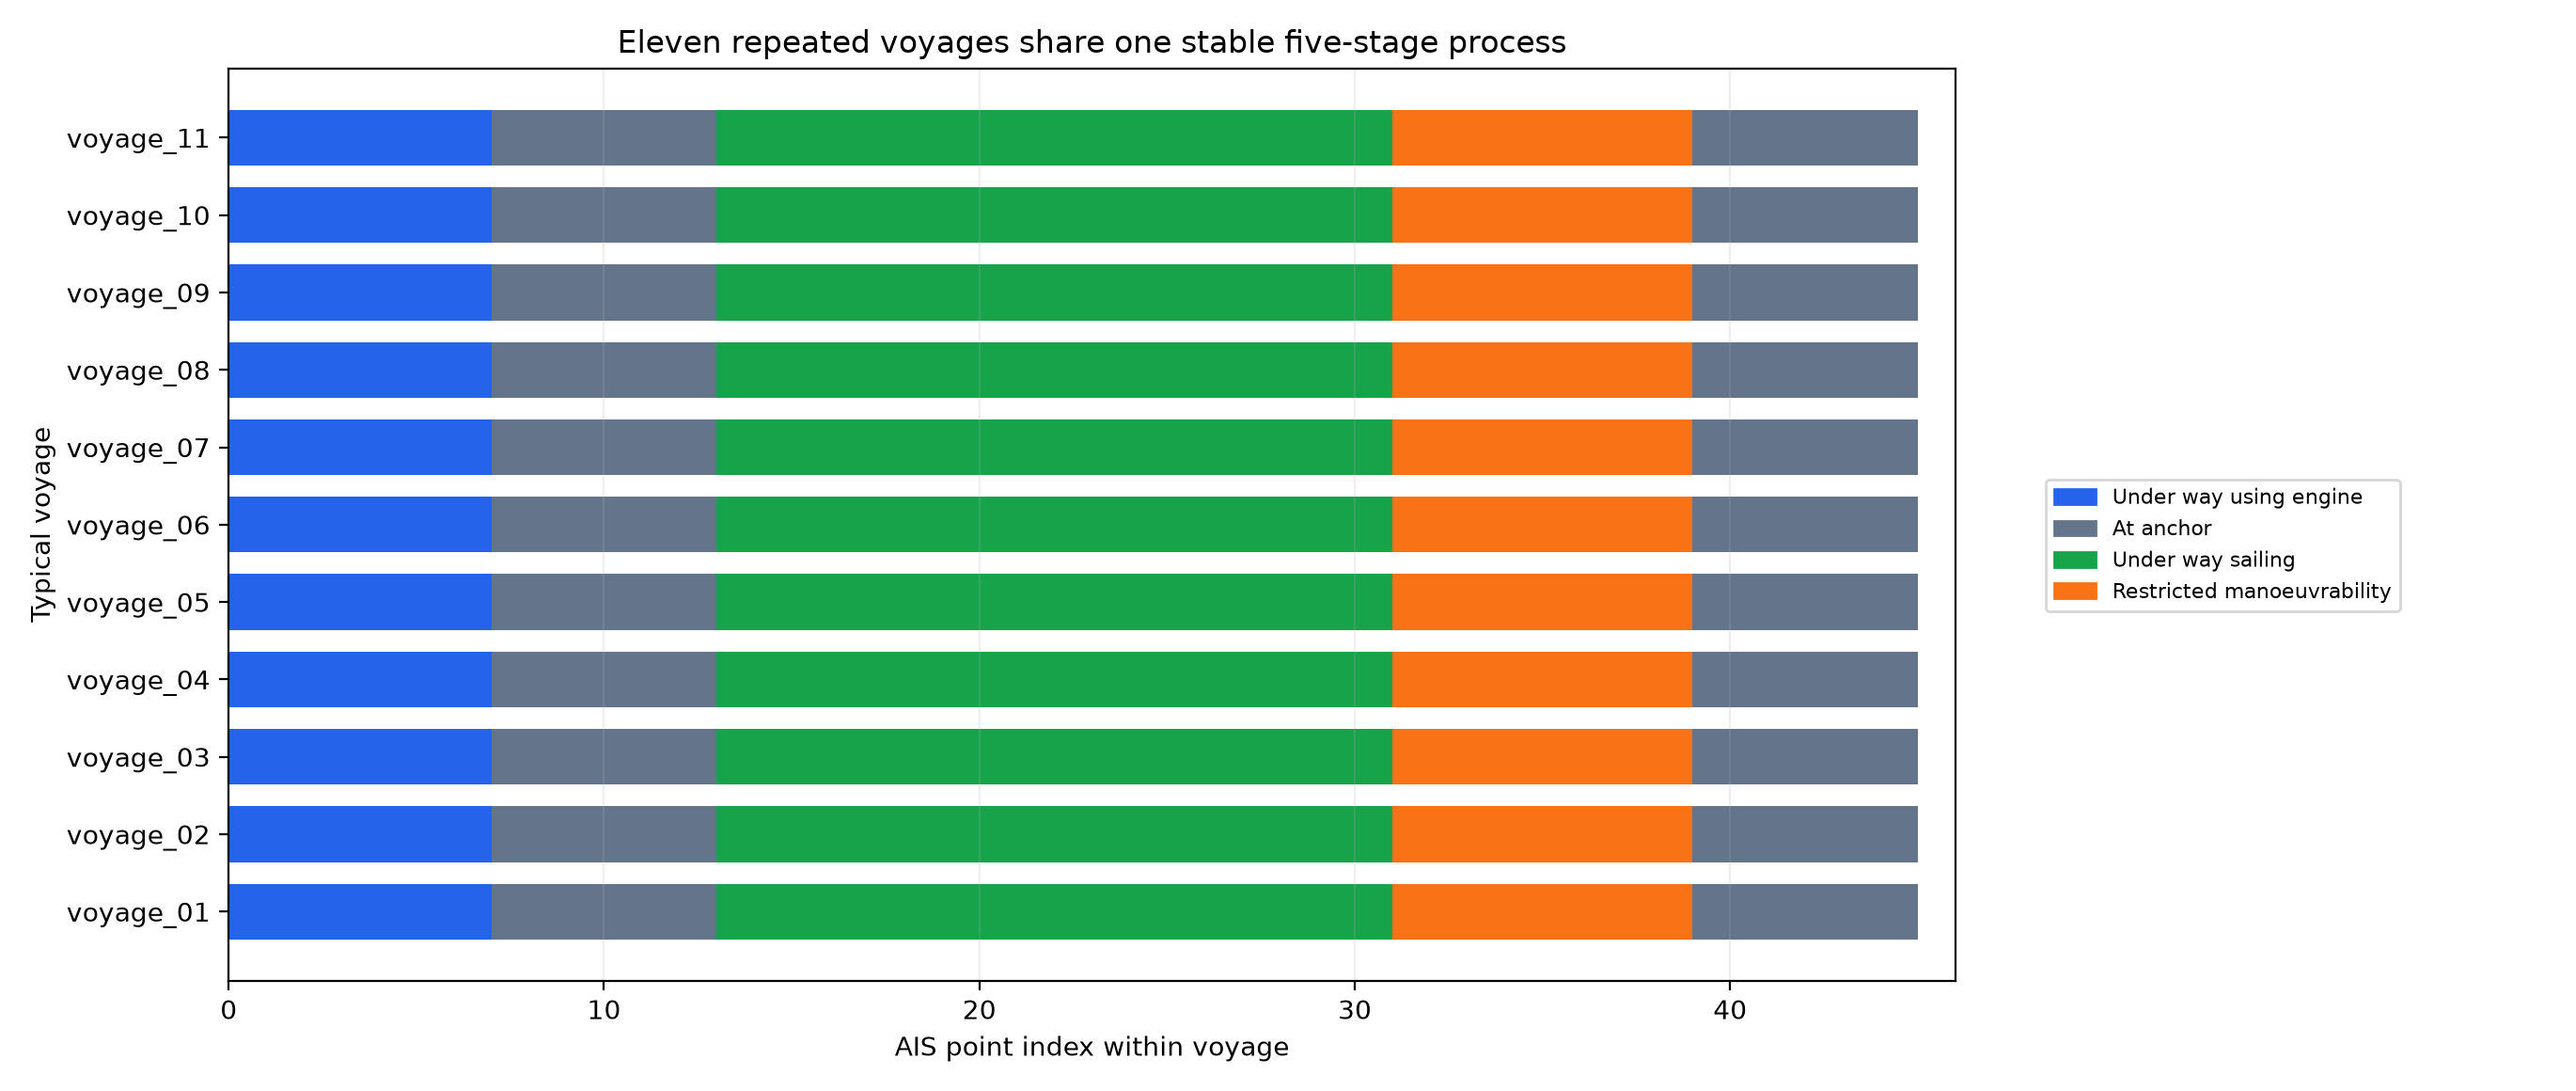

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path)
print(points.groupby(['trajectory_id', 'nav_status']).size())
# Order contiguous nav_status runs by point_index for every trajectory and compare the resulting sequences.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/repeated_voyage_stage_sequence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeated_navigational_status_sequence",
  "insight": "The typical voyage process is stable across 11 trajectories: Under way using engine when leaving Harbour Orion, followed by an intermediate At anchor stage, Under way sailing, Restricted manoeuvrability on the approach to Harbour Lyra, and At anchor after arrival.",
  "insight_value": {
    "typical_trajectories": 11,
    "stage_sequence": [
      "Under way using engine",
      "At anchor",
      "Under way sailing",
      "Restricted manoeuvrability",
      "At anchor"
    ]
  },
  "plot": {
    "plot_type": "repeated_state_timeline",
    "title": "Repeated Voyage Stage Sequence",
    "file": "visualizations/repeated_voyage_stage_sequence.png",
    "description": "Each row is one normal voyage. Its colored runs show the same five-stage status sequence."
  },
  "question": "What navigational-status sequence recurs across this vessel's repeated voyages, and where are its stable stage boundaries?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path)\nprint(points.groupby(['trajectory_id', 'nav_status']).size())\n# Order contiguous nav_status runs by point_index for every trajectory and compare the resulting sequences.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "navigation_status",
    "gps_position",
    "harbour_location",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How does course change at the transition from Under way sailing to Restricted manoeuvrability, and how is that change positioned relative to the destination harbour?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

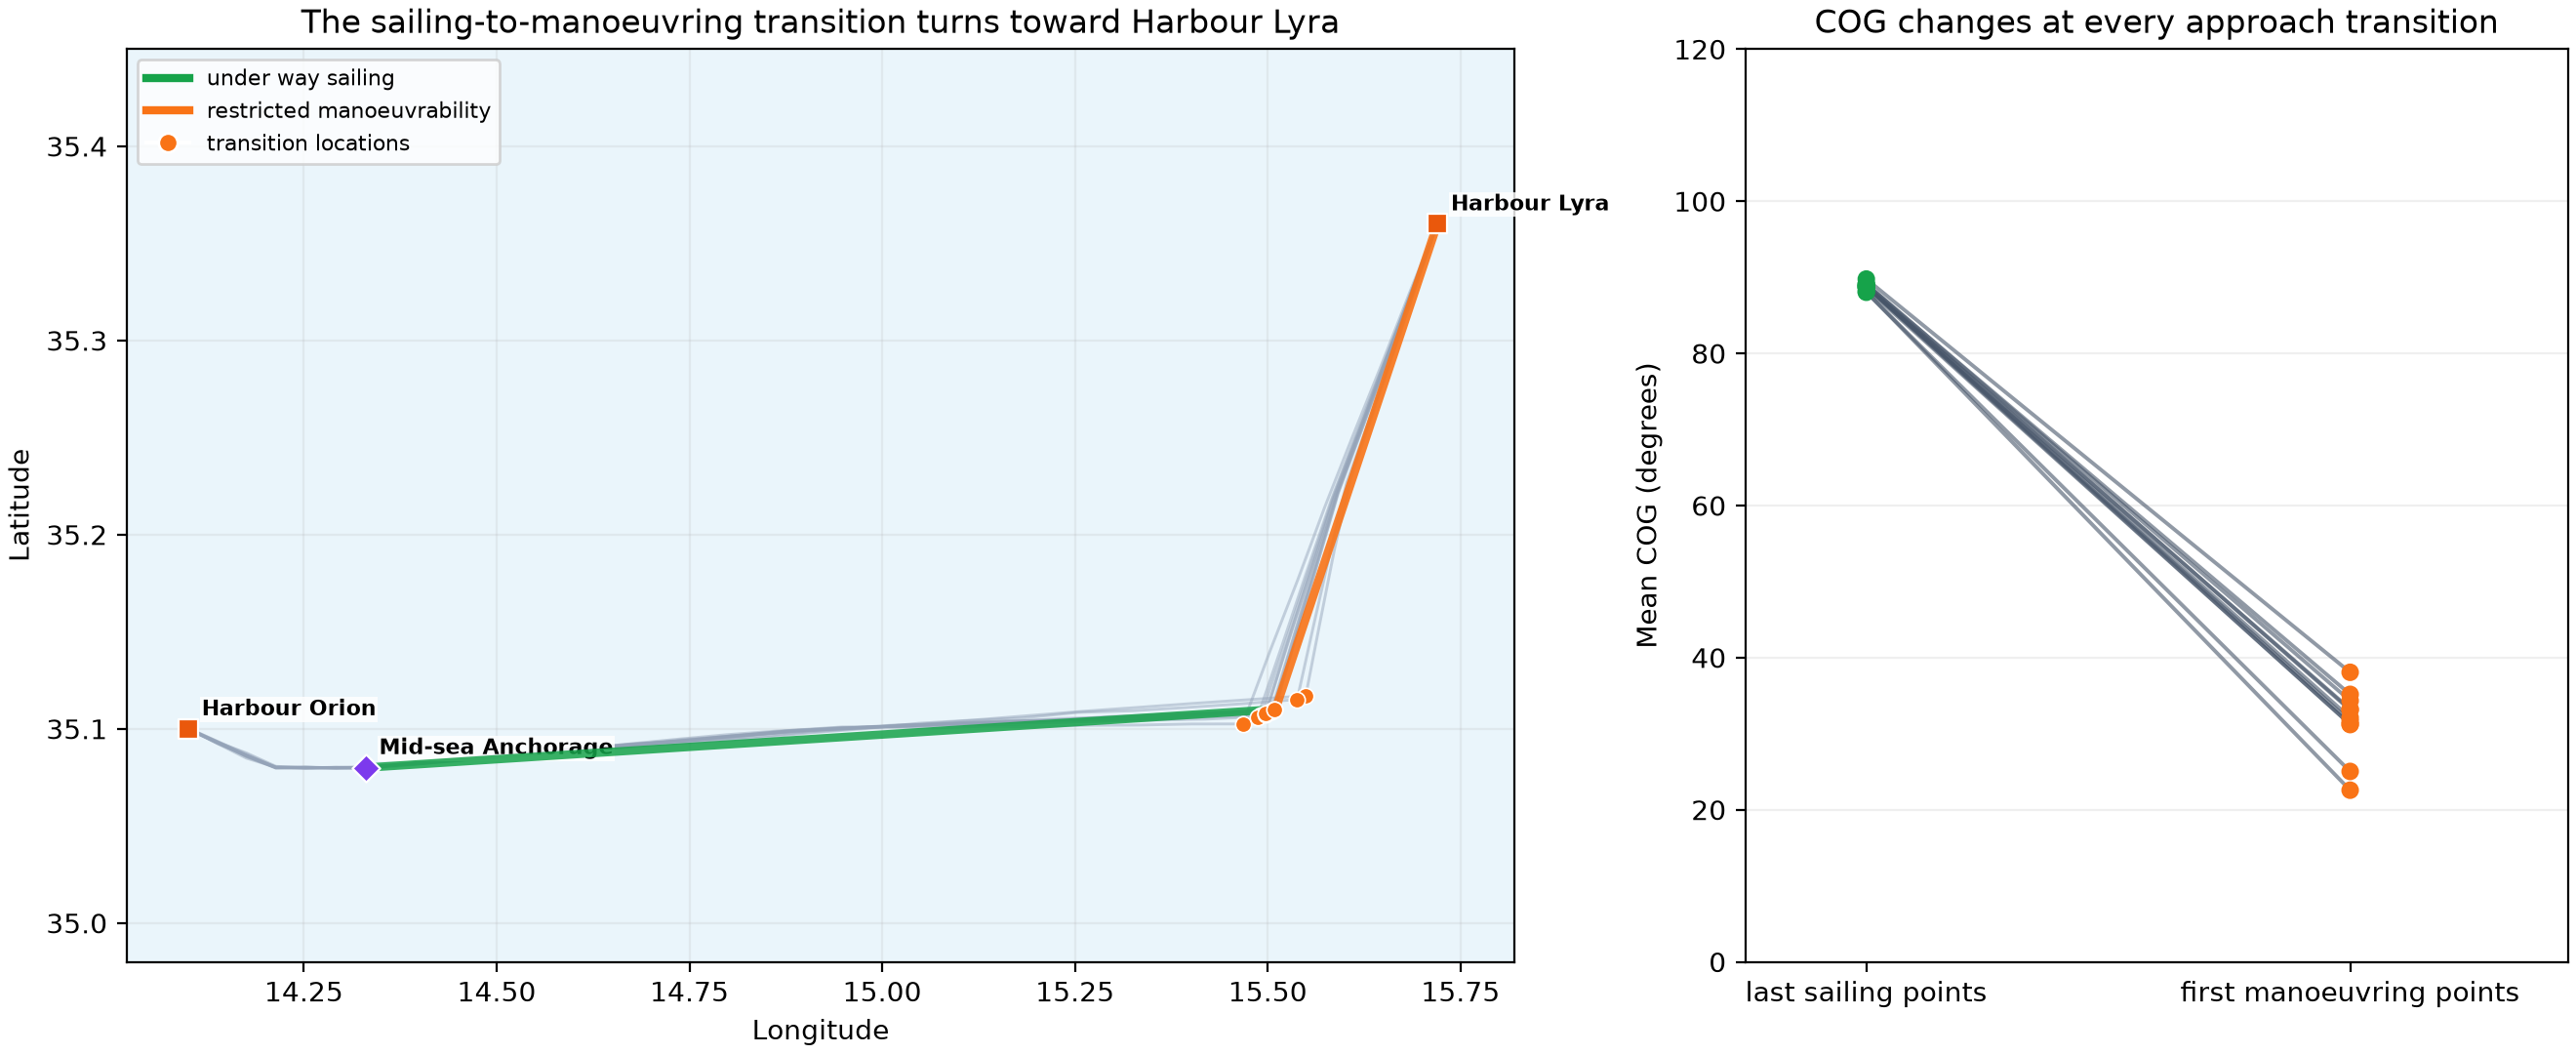

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path)
# For each trajectory, compare COG in the final three Under way sailing points with COG in the first three Restricted manoeuvrability points; join harbour_locations.csv to map the destination.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/approach_turn_course_change.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "course_change_at_process_transition",
  "insight": "Every normal transition from Under way sailing to Restricted manoeuvrability contains a large course change. The turn redirects the vessel from its eastbound transit toward Harbour Lyra, where the final anchoring stage occurs.",
  "insight_value": {
    "normal_voyages_with_turn": 11,
    "course_change_deg_range": [
      52,
      66
    ],
    "destination": "Harbour Lyra"
  },
  "plot": {
    "plot_type": "map_and_course_change_slope_plot",
    "title": "Approach Turn Course Change",
    "file": "visualizations/approach_turn_course_change.png",
    "description": "The map locates the common approach turn; the paired COG points quantify its repeated change for each normal voyage."
  },
  "question": "How does course change at the transition from Under way sailing to Restricted manoeuvrability, and how is that change positioned relative to the destination harbour?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path)\n# For each trajectory, compare COG in the final three Under way sailing points with COG in the first three Restricted manoeuvrability points; join harbour_locations.csv to map the destination.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "navigation_status",
    "course_over_ground",
    "gps_position",
    "harbour_location",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Which trajectory does not follow the usual process, and how do its intermediate anchoring, average SOG, turning location, and ROT differ from the typical voyages?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

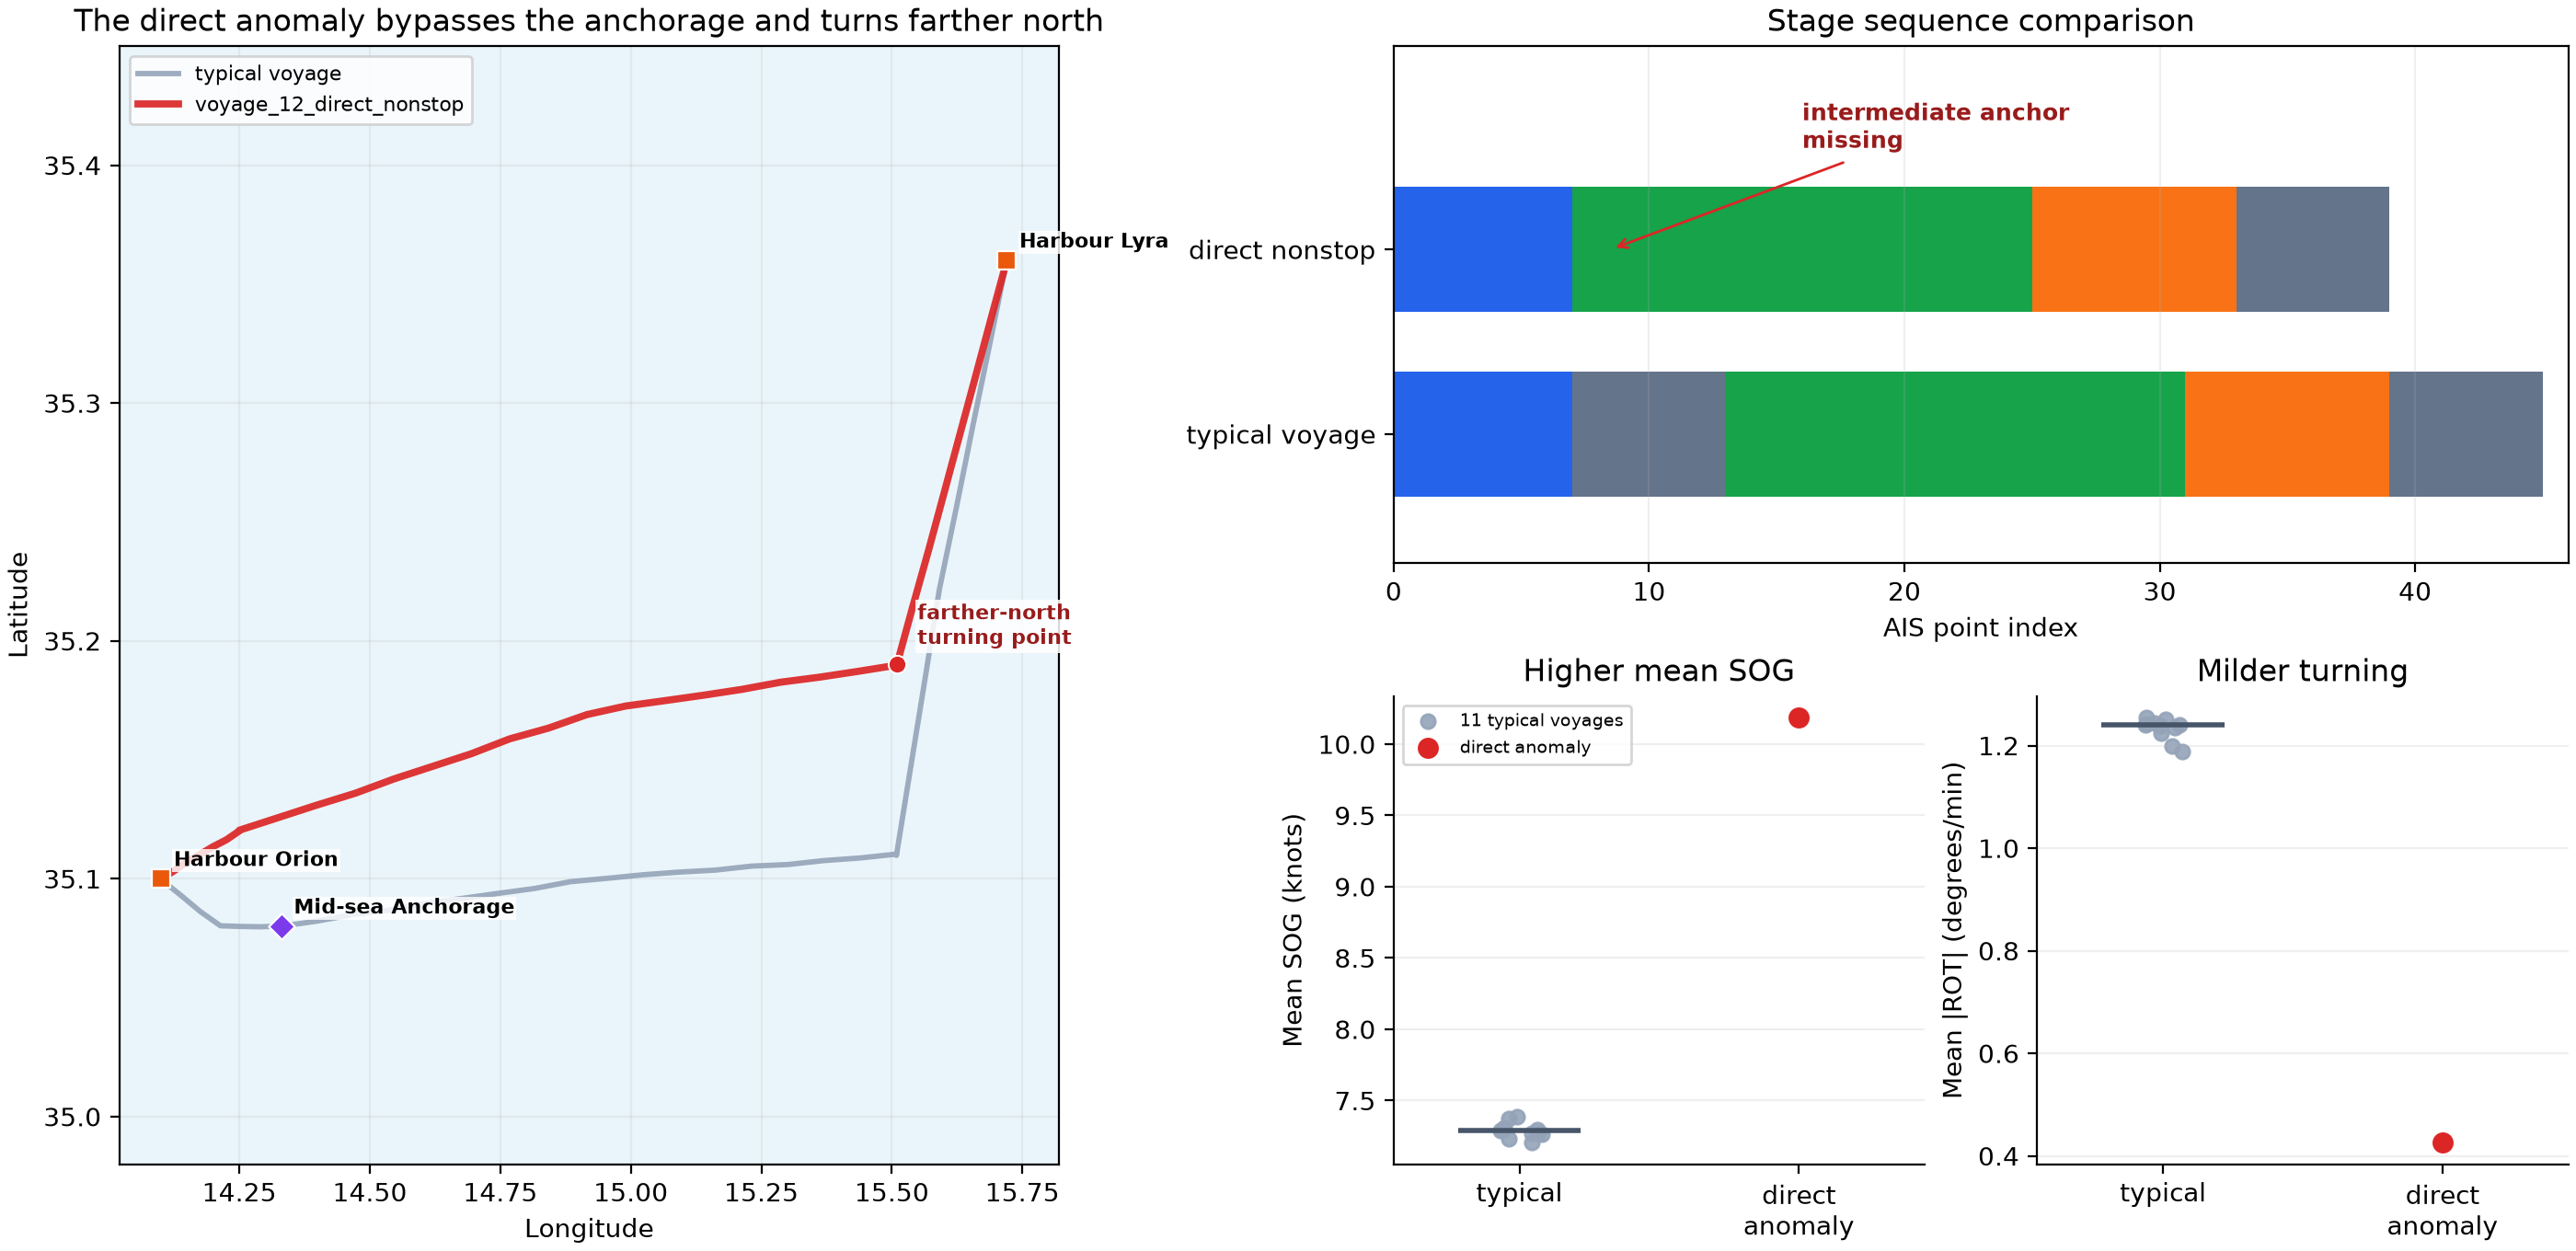

In [ ]:
import pandas as pd
points = pd.read_csv(dataset_path)
# Order contiguous nav_status runs by trajectory, then compare trajectory-level mean SOG and mean absolute ROT. Use harbour_locations.csv and trajectory geometry to locate each final approach turning point.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/direct_nonstop_anomaly.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "process_and_kinematic_anomaly",
  "insight": "voyage_12_direct_nonstop is the sole process anomaly. It does not anchor at the intermediate anchorage before arriving at Harbour Lyra, and its mean SOG is higher than for the typical voyages (10.19 versus 7.29 knots). Its turning point is farther north, so the final turn is milder and its mean absolute ROT is substantially lower (0.43 versus 1.24 degrees per minute).",
  "insight_value": {
    "anomalous_trajectory_id": "voyage_12_direct_nonstop",
    "missing_stage": "intermediate At anchor",
    "typical_voyages": 11,
    "anomaly_mean_sog_knots": 10.19,
    "typical_median_mean_sog_knots": 7.29,
    "anomaly_mean_absolute_rot_deg_per_min": 0.43,
    "typical_median_mean_absolute_rot_deg_per_min": 1.24,
    "anomaly_turning_point_latitude": 35.19,
    "typical_turning_point_latitude": "about 35.11"
  },
  "plot": {
    "plot_type": "route_stage_sequence_and_kinematic_comparison",
    "title": "Direct-Nonstop Process and Kinematic Anomaly",
    "file": "visualizations/direct_nonstop_anomaly.png",
    "description": "The anomaly bypasses the mid-sea anchorage and turns farther north; the point distributions compare its higher mean SOG and lower mean absolute ROT with the 11 typical voyages."
  },
  "question": "Which trajectory does not follow the usual process, and how do its intermediate anchoring, average SOG, turning location, and ROT differ from the typical voyages?",
  "code": "import pandas as pd\npoints = pd.read_csv(dataset_path)\n# Order contiguous nav_status runs by trajectory, then compare trajectory-level mean SOG and mean absolute ROT. Use harbour_locations.csv and trajectory geometry to locate each final approach turning point.",
  "insight_type": "exception_deviation",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "navigation_status",
    "gps_position",
    "harbour_location",
    "point_speed",
    "rate_of_turn",
    "vessel_id",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 9)

Across 11 repeated voyages, MV Aurora follows a stable five-stage sailing process with an intermediate anchorage and a large final harbour-approach turn. voyage_12_direct_nonstop is the only exception: it bypasses the intermediate anchorage, maintains a higher average SOG, and takes a farther-north, lower-ROT approach to Harbour Lyra.